# Industry Project: Shipping a New Model Version Safely (Production-Style)

> **Who is this notebook for?** Someone who can train a model and put it behind an API, and now wonders:
> *"My new model is better offline. How do I switch production over without breaking things for real users?"*
> No servers or cloud accounts are needed: we build a small **traffic simulator** in Python and run every rollout
> strategy on it. Every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from the others in `16_Deployment/`

| `01_deployment_concepts.ipynb` and friends | This notebook |
|---|---|
| Name the strategies (blue-green, canary, shadow) with ASCII diagrams | **Implements** each one in Python and runs it on simulated production traffic |
| One model, one deployment | A current model **v1** and three **release candidates**, one good and two with realistic production bugs |
| "Increase canary traffic if metrics are good" | **Automatic** promote / extend / rollback decisions from explicit guardrails with confidence intervals |
| No experiment design | **A/B test by user hash** with a sample-ratio-mismatch check |
| No operational docs | **Feature flags** with a kill switch, and a generated **deployment runbook** |

---

### The business problem

You work at a food-delivery app. When a customer opens a restaurant page, the app shows **"Arrives in 32 min"**. That number comes from an **ETA model** (estimated time of arrival).

- **v1** (in production for a year): a simple linear model using distance and number of items.
- **v2** (new): gradient-boosted trees with more features (restaurant prep time from the feature store, rain, rush hour, couriers nearby). Offline, it is clearly better.

Why not just replace v1 with v2? Because **offline results don't guarantee production results**:
- a feature that existed in the training data may be **missing or different in production** (training-serving skew),
- the new model may be **slower** or call a new service that **times out**,
- customers may **react** to the new numbers differently.

Every bad release costs real money: a too-optimistic ETA means late food, angry customers and refunds; an outage on the ETA service blocks orders. **Success** = v2 reaches 100% of traffic if, and only if, it is really better, and any bad candidate is stopped automatically while it touches as few customers as possible.

---

### Table of Contents
1. Setup and one central config
2. Data, model v1, model v2 and three release candidates
3. Batch vs. online deployment (and a release gate for batch jobs)
4. A simulated production environment
5. Shadow deployment: run v2 silently next to v1
6. Canary rollout with automatic checks and rollback
7. Blue-green deployment with smoke tests
8. A/B test by user hash
9. Feature flags: decouple deploy from release
10. Which strategy when?
11. The deployment runbook
12. Automated tests for the rollout machinery
13. Summary, exercises and resources

---
## 1. Setup and one central config

All release rules (stages, guardrails, tolerances) live in one frozen dataclass. In a company these would be reviewed like code, because they decide whether a release goes ahead without a human.

In [1]:
import hashlib                          # deterministic user bucketing (same user -> same model)
import logging                          # status messages with timestamps
import warnings
from dataclasses import dataclass, field
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats                 # chi-square and normal distribution for the statistics
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("rollout")
SEED = 42


@dataclass(frozen=True)
class RolloutConfig:
    canary_stages_pct: tuple = (1, 5, 25, 50)   # % of USERS on the candidate; after the last stage -> 100%
    requests_per_chunk: int = 20_000            # traffic observed per check (think: ~30 minutes of traffic)
    min_canary_requests: int = 400              # never decide on less data than this
    max_chunks_per_stage: int = 4               # if still not enough data after this: stop and ask a human
    max_error_rate_increase: float = 0.005      # canary may have at most +0.5 percentage points more errors
    latency_slo_p95_ms: float = 50.0            # absolute latency SLO
    max_p95_ratio: float = 1.5                  # canary p95 may be at most 1.5x the control p95
    late_margin_min: float = 10.0               # "broken promise": food arrives > 10 min after the shown ETA


CFG = RolloutConfig()
print(CFG)

RolloutConfig(canary_stages_pct=(1, 5, 25, 50), requests_per_chunk=20000, min_canary_requests=400, max_chunks_per_stage=4, max_error_rate_increase=0.005, latency_slo_p95_ms=50.0, max_p95_ratio=1.5, late_margin_min=10.0)


---
## 2. Data, model v1, model v2 and three release candidates

The data is **simulated** delivery history (in real life: a query over completed orders, where the true delivery time is known about 40 minutes after ordering). The true delivery time depends on restaurant prep time, distance, rush hour, rain and courier availability, plus a lot of randomness (traffic lights, slow elevators). We keep a `user_id` and a `zone` because the rollout strategies route traffic by user and by region.

In [2]:
ZONES = ["center", "north", "south", "east", "west"]
HOUR_WEIGHTS = np.array([1, 1, 1, 1, 1, 1, 2, 3, 4, 4, 5, 8, 12, 11, 6, 5, 6, 9, 13, 14, 11, 7, 4, 2], float)


def make_orders(n: int, seed: int) -> pd.DataFrame:
    """Simulated orders with the TRUE delivery time (known ~40 min later in real life)."""
    rng = np.random.default_rng(seed)
    hour = rng.choice(24, n, p=HOUR_WEIGHTS / HOUR_WEIGHTS.sum())        # lunch and dinner peaks
    is_rush = np.isin(hour, [12, 13, 18, 19, 20])
    df = pd.DataFrame({
        "user_id": [f"u{u}" for u in rng.integers(1, 60_000, n)],      # users come back: repeated IDs
        "zone": rng.choice(ZONES, n, p=[0.3, 0.2, 0.2, 0.15, 0.15]),
        "distance_km": rng.gamma(2.0, 1.6, n).clip(0.3, 15).round(2),
        "items": rng.integers(1, 8, n),
        "prep_min": rng.normal(14, 5, n).clip(4, 40).round(1),          # restaurant's typical prep time (feature store)
        "hour": hour,
        "is_rush": is_rush.astype(int),
        "is_raining": (rng.random(n) < 0.15).astype(int),
    })
    df["couriers_nearby"] = rng.poisson(np.where(is_rush, 2.0, 4.5))
    zone_delay = df["zone"].map({"center": 3.0, "north": 0.0, "south": 1.0, "east": 0.5, "west": 0.0})
    df["actual_min"] = (5 + df["prep_min"] * (1 + 0.04 * df["items"])
                        + df["distance_km"] * 3.0 * (1 + 0.35 * df["is_rush"]) * (1 + 0.25 * df["is_raining"])
                        + 8 / (1 + df["couriers_nearby"]) + zone_delay
                        + rng.gamma(2.0, 2.5, n)).round(1)                 # randomness nobody can predict
    return df


history = make_orders(12_000, seed=SEED)
history[["user_id", "zone", "distance_km", "items", "prep_min", "is_rush", "couriers_nearby", "actual_min"]].head()

,user_id,zone,distance_km,items,prep_min,is_rush,couriers_nearby,actual_min
0,u55270,center,0.35,1,8.1,1,3,23.8
1,u31084,east,1.10,2,17.0,0,3,42.2
2,u36847,west,3.34,5,24.8,1,1,62.0
3,u21218,north,1.08,2,14.9,1,0,36.9
4,u53440,west,5.59,6,9.7,0,5,37.8


In [3]:
V1_FEATURES = ["distance_km", "items"]
V2_FEATURES = ["distance_km", "items", "prep_min", "hour", "is_rush", "is_raining", "couriers_nearby"]

train, test = train_test_split(history, test_size=0.3, random_state=SEED)
model_v1 = Ridge().fit(train[V1_FEATURES], train["actual_min"])
model_v2 = GradientBoostingRegressor(n_estimators=150, max_depth=3, learning_rate=0.1,
                                     random_state=SEED).fit(train[V2_FEATURES], train["actual_min"])

offline = pd.DataFrame({
    "model": ["v1 (Ridge, 2 features)", "v2 (GBM, 7 features)"],
    "MAE_min": [mean_absolute_error(test["actual_min"], model_v1.predict(test[V1_FEATURES])),
                mean_absolute_error(test["actual_min"], model_v2.predict(test[V2_FEATURES]))],
}).round(2)
offline

,model,MAE_min
0,"v1 (Ridge, 2 features)",6.01
1,"v2 (GBM, 7 features)",2.98


v2 is clearly better **offline**. Now the realistic part. A model in production is more than a fitted object: it is wrapped in a service that fetches features, has latency and can fail. We define an `Endpoint` that bundles the model with its production behaviour, and create **three release candidates** that all contain the *same* v2 model:

| Candidate | What is different in production | Real-world cause |
|---|---|---|
| `v2` | nothing: works as in training | the happy path |
| `v2-skew` | `prep_min` arrives as **0** | the new feature-store table was never back-filled in production (training-serving skew) |
| `v2-timeouts` | **3%** of requests time out | v2 calls a new, under-provisioned feature service |

Latency and errors are **simulated** with fixed, made-up parameters (we are not running servers); the predictions are **real** model outputs.

In [4]:
@dataclass
class Endpoint:
    """A deployed model version: the model + how it behaves in production."""
    name: str
    model: object
    features: list
    latency_median_ms: float               # simulated service latency (not measured)
    error_rate: float = 0.001              # share of requests that fail (timeouts, 5xx)
    broken_feature: str | None = None      # a feature that arrives as 0 in production (skew bug)
    timeout_ms: float = 200.0

    def serve(self, orders: pd.DataFrame, rng: np.random.Generator) -> pd.DataFrame:
        X = orders[self.features].copy()
        if self.broken_feature:                                     # the production-only bug
            X[self.broken_feature] = 0.0
        pred = self.model.predict(X) if len(X) else np.array([])
        latency = rng.lognormal(np.log(self.latency_median_ms), 0.4, len(X))
        failed = rng.random(len(X)) < self.error_rate
        return pd.DataFrame({"version": self.name,
                             "pred_min": np.where(failed, np.nan, pred),          # failed -> no prediction
                             "latency_ms": np.where(failed, self.timeout_ms, latency),
                             "failed": failed}, index=orders.index)


V1 = Endpoint("v1", model_v1, V1_FEATURES, latency_median_ms=8)
CANDIDATES = {
    "v2": Endpoint("v2", model_v2, V2_FEATURES, latency_median_ms=10),
    "v2-skew": Endpoint("v2-skew", model_v2, V2_FEATURES, latency_median_ms=10, broken_feature="prep_min"),
    "v2-timeouts": Endpoint("v2-timeouts", model_v2, V2_FEATURES, latency_median_ms=10, error_rate=0.03),
}
print("v1 + candidates:", [V1.name] + list(CANDIDATES))

v1 + candidates: ['v1', 'v2', 'v2-skew', 'v2-timeouts']


---
## 3. Batch vs. online deployment (and a release gate for batch jobs)

Before choosing a rollout strategy, know **how** the model is used:

| | **Batch** (offline) deployment | **Online** (real-time) deployment |
|---|---|---|
| How it runs | Scheduled job scores many rows, writes a table | Service answers each request in milliseconds |
| Examples | nightly churn scores, weekly demand forecast, prep-time estimates per restaurant | fraud check at checkout, ETA on the app, search ranking |
| How a new version is released | Run old and new **side by side on the same input**, compare, then **swap the table** the consumers read | Route a **share of live traffic** (shadow, canary, blue-green, A/B) |
| Rollback | Point consumers back to yesterday's table | Route traffic back to the old version |
| Risk | Low: you see every output before anyone uses it | Higher: users see outputs immediately |

For batch jobs, the safety mechanism is a **release gate**: compute the new outputs, compare them with the old ones and with a labelled "golden" set, and publish only if the checks pass. Big unexplained shifts block the release even if the new model "looks better", because a big shift usually means a bug.

In [5]:
def batch_release_gate(old_pred: np.ndarray, new_pred: np.ndarray, actual: np.ndarray,
                       max_mean_shift_min: float = 2.0) -> dict:
    """Compare two batch outputs on the same input. Publish only if the new one is better AND not wildly different."""
    report = {
        "mae_old": round(float(np.mean(np.abs(actual - old_pred))), 2),
        "mae_new": round(float(np.mean(np.abs(actual - new_pred))), 2),
        "mean_shift_min": round(float(np.mean(new_pred - old_pred)), 2),       # systematic change of all outputs
        "share_changed_over_5min": round(float(np.mean(np.abs(new_pred - old_pred) > 5)), 3),
    }
    report["publish"] = bool(report["mae_new"] < report["mae_old"] and abs(report["mean_shift_min"]) <= max_mean_shift_min)
    return report


golden = make_orders(3_000, seed=7)                          # last week's orders with known delivery times
gate_rng = np.random.default_rng(SEED)
old_out = V1.serve(golden, gate_rng)["pred_min"].to_numpy()
rows = []
for name in ["v2", "v2-skew"]:                               # batch jobs don't have timeouts in this sense
    new_out = CANDIDATES[name].serve(golden, gate_rng)["pred_min"].to_numpy()
    ok = ~np.isnan(old_out) & ~np.isnan(new_out)
    rows.append({"candidate": name, **batch_release_gate(old_out[ok], new_out[ok], golden["actual_min"].to_numpy()[ok])})
pd.DataFrame(rows)

,candidate,mae_old,mae_new,mean_shift_min,share_changed_over_5min,publish
0,v2,5.95,2.89,0.12,0.441,True
1,v2-skew,5.95,12.04,-11.81,0.945,False


The gate publishes `v2` and blocks `v2-skew`: the skewed model's outputs shifted down by many minutes on average (it thinks every restaurant cooks instantly), which is exactly the kind of change a human should look at before customers see it.

The rest of the notebook is about the harder case: **online** deployment, where the model answers live requests.

---
## 4. A simulated production environment

To compare strategies we need "production". Our simulator:
- generates a chunk of live orders (`make_orders`), each from a `user_id`,
- a **router** decides which endpoint serves each request,
- the endpoint returns a prediction, a latency and maybe an error,
- about 40 minutes later the **true** delivery time arrives, so we can measure quality.

Two building blocks are used everywhere below:

**1. Deterministic user bucketing.** `bucket(user_id, salt)` hashes the user ID into a number 0-99. The same user always lands in the same bucket, on every server, without storing anything. "Send 5% of users to the canary" becomes `bucket < 5`. A different `salt` per experiment gives an independent split, so experiments don't overlap by accident.

**2. Arm metrics.** For each group ("arm") of requests we compute the error rate, p95 latency, mean absolute error (MAE) in minutes, and the **late rate** = share of orders that arrived more than 10 minutes after the promised ETA (the number customer support cares about).

In [6]:
def bucket(user_id: str, salt: str, n_buckets: int = 100) -> int:
    """Map a user to a stable bucket 0..n_buckets-1. Same input -> same output, on any machine."""
    digest = hashlib.sha256(f"{salt}:{user_id}".encode()).hexdigest()
    return int(digest[:8], 16) % n_buckets


def arm_metrics(served: pd.DataFrame, actual: pd.Series) -> dict:
    """Quality and reliability metrics for one group of served requests."""
    ok = ~served["failed"]                                  # failed requests have no prediction
    y = actual.reindex(served.index)                         # true delivery time for exactly these requests
    abs_err = (y - served["pred_min"]).abs()[ok]
    return {"requests": len(served),
            "error_rate": served["failed"].mean(),
            "p95_latency_ms": np.percentile(served["latency_ms"], 95) if len(served) else np.nan,
            "mae_min": abs_err.mean(),
            "late_rate": (y > served["pred_min"] + CFG.late_margin_min)[ok].mean()}


print("bucket('u123', 'eta-canary') =", bucket("u123", "eta-canary"), "(always the same)")
print("bucket('u123', 'eta-ab-test') =", bucket("u123", "eta-ab-test"), "(different salt -> independent split)")

bucket('u123', 'eta-canary') = 42 (always the same)
bucket('u123', 'eta-ab-test') = 19 (different salt -> independent split)


---
## 5. Shadow deployment: run v2 silently next to v1

In **shadow mode** (also called *dark launch*), v1 still answers every customer. Each request is **also** sent to the candidate in the background; its answer is **logged, never shown**. Later, when true delivery times arrive, we compare both models on **exactly the same requests** (a *paired* comparison, the most precise comparison possible).

- **Zero user risk**: customers never see the candidate's output, and its latency doesn't slow them down (the copy is sent asynchronously).
- **Cost**: you pay for double the inference compute during the shadow period.
- **Limit**: it can't measure how customers *react* to new ETAs (that needs an A/B test, Section 8).

In [7]:
def run_shadow(candidate: Endpoint, orders: pd.DataFrame, seed: int) -> dict:
    """v1 serves everyone; the candidate sees a copy of every request; compare on the same requests."""
    rng = np.random.default_rng(seed)
    live, shadow = V1.serve(orders, rng), candidate.serve(orders, rng)
    both_ok = ~live["failed"] & ~shadow["failed"]
    actual = orders.loc[both_ok, "actual_min"]
    err_live = (actual - live.loc[both_ok, "pred_min"]).abs()
    err_shadow = (actual - shadow.loc[both_ok, "pred_min"]).abs()
    diff = err_shadow - err_live                               # paired: same order, two models
    ci = 1.96 * diff.std() / np.sqrt(len(diff))                # 95% confidence interval half-width
    return {"candidate": candidate.name,
            "mae_v1": err_live.mean(), "mae_candidate": err_shadow.mean(),
            "mae_change_min": diff.mean(), "ci95": f"[{diff.mean() - ci:+.2f}, {diff.mean() + ci:+.2f}]",
            "mean_pred_shift_min": (shadow["pred_min"] - live["pred_min"]).mean(),
            "candidate_error_rate": shadow["failed"].mean(),
            "candidate_p95_ms": np.percentile(shadow["latency_ms"], 95)}


shadow_traffic = make_orders(CFG.requests_per_chunk, seed=101)
shadow_report = pd.DataFrame([run_shadow(c, shadow_traffic, seed=5) for c in CANDIDATES.values()])
shadow_report.round(3)

,candidate,mae_v1,mae_candidate,mae_change_min,ci95,mean_pred_shift_min,candidate_error_rate,candidate_p95_ms
0,v2,6.082,2.932,-3.150,"[-3.21, -3.09]",-0.023,0.001,19.335
1,v2-skew,6.082,11.913,5.831,"[+5.73, +5.94]",-11.889,0.001,19.335
2,v2-timeouts,6.074,2.930,-3.144,"[-3.21, -3.08]",-0.034,0.029,22.089


**Reading the shadow report:**
- `v2`: lower MAE than v1 on the very same orders, the confidence interval is entirely below zero, and predictions barely shift on average. Healthy.
- `v2-skew`: the MAE gets **worse**, and `mean_pred_shift_min` reveals *why*: predictions dropped by many minutes on average. In real life, this shift is visible on a dashboard **within minutes**, long before any customer is affected. This alone justifies shadow mode for risky changes.
- `v2-timeouts`: prediction quality is fine (it's the same model), but about 3% of shadow calls fail. Shadow mode catches this too, without a single customer seeing an error.

---
## 6. Canary rollout with automatic checks and rollback

A **canary** release sends a *small* share of real users to the candidate, compares them with the users still on v1 (the **control**) *at the same time*, and only then increases the share: 1% -> 5% -> 25% -> 50% -> 100%.

This follows Google's SRE guidance on canarying ([SRE Workbook, "Canarying Releases"](https://sre.google/workbook/canarying-releases/)):
- compare canary vs. a **concurrent control** (not "before vs. after", which mixes in time effects like lunch rush),
- use a **small set of user-facing metrics** (errors, latency, quality), not noisy ones like CPU,
- require **enough data** before deciding, and roll back automatically when the canary is clearly worse.

Our automatic decision at each stage:

| Check | Rule | Catches |
|---|---|---|
| enough data | canary requests >= 400, otherwise observe another chunk (**extend**) | deciding on noise |
| errors | canary error rate <= control + 0.5 pp | timeouts, crashes |
| latency | canary p95 <= 50 ms SLO **and** <= 1.5x control p95 | slow models / dependencies |
| quality | 95% CI of (canary MAE - control MAE) must **not** lie entirely above 0 | skew, bad models |

Any failed check -> **rollback** (all users back to v1, page the owner). All checks pass -> **promote** to the next stage.

In [8]:
def compare_arms(control: pd.DataFrame, canary: pd.DataFrame, actual: pd.Series, cfg=CFG) -> dict:
    """Apply the guardrails to one stage's data and return metrics, checks and a decision."""
    m_ctl, m_can = arm_metrics(control, actual), arm_metrics(canary, actual)
    err_ctl = (actual - control["pred_min"]).abs().dropna()
    err_can = (actual - canary["pred_min"]).abs().dropna()
    diff = err_can.mean() - err_ctl.mean()                                   # unpaired: different users
    se = np.sqrt(err_can.var() / max(len(err_can), 1) + err_ctl.var() / len(err_ctl))
    checks = {
        "enough_data": m_can["requests"] >= cfg.min_canary_requests,
        "errors_ok": m_can["error_rate"] <= m_ctl["error_rate"] + cfg.max_error_rate_increase,
        "latency_ok": (m_can["p95_latency_ms"] <= cfg.latency_slo_p95_ms
                       and m_can["p95_latency_ms"] <= cfg.max_p95_ratio * m_ctl["p95_latency_ms"]),
        "quality_ok": not (diff - 1.96 * se > 0),                             # CI entirely above 0 = clearly worse
    }
    if not checks["enough_data"]:
        decision = "extend"
    elif all(checks.values()):
        decision = "promote"
    else:
        decision = "rollback"
    return {"canary_requests": m_can["requests"], "control_error": m_ctl["error_rate"],
            "canary_error": m_can["error_rate"], "control_p95": m_ctl["p95_latency_ms"],
            "canary_p95": m_can["p95_latency_ms"], "control_mae": m_ctl["mae_min"], "canary_mae": m_can["mae_min"],
            "mae_diff_ci": (round(diff - 1.96 * se, 2), round(diff + 1.96 * se, 2)),
            "failed_checks": [k for k, v in checks.items() if not v], "decision": decision}


def run_canary(candidate: Endpoint, cfg=CFG, seed: int = 1000) -> tuple[str, pd.DataFrame]:
    """Walk through the canary stages; stop at the first rollback. Returns (outcome, per-stage history)."""
    rng = np.random.default_rng(seed)
    history, chunk_seed = [], seed
    for stage in cfg.canary_stages_pct:
        served, orders_seen = [], []
        for chunk in range(cfg.max_chunks_per_stage):                         # observe traffic chunk by chunk
            chunk_seed += 1
            orders = make_orders(cfg.requests_per_chunk, seed=chunk_seed)
            to_canary = np.array([bucket(u, "eta-canary") < stage for u in orders["user_id"]])
            served.append(pd.concat([V1.serve(orders[~to_canary], rng),
                                     candidate.serve(orders[to_canary], rng)]).sort_index())  # same row order as orders
            orders_seen.append(orders)
            all_served, all_orders = pd.concat(served, ignore_index=True), pd.concat(orders_seen, ignore_index=True)
            is_canary = (all_served["version"] == candidate.name).to_numpy()
            verdict = compare_arms(all_served[~is_canary], all_served[is_canary], all_orders["actual_min"])
            if verdict["decision"] != "extend":
                break
        history.append({"candidate": candidate.name, "stage_pct": stage, "chunks": chunk + 1, **verdict})
        log.info("%s @ %d%%: %s %s", candidate.name, stage, verdict["decision"].upper(), verdict["failed_checks"])
        if verdict["decision"] == "rollback":
            return f"ROLLED BACK at {stage}%", pd.DataFrame(history)
        if verdict["decision"] == "extend":                                    # still not enough data: escalate
            return f"HALTED at {stage}% (not enough data, human decision needed)", pd.DataFrame(history)
    return "PROMOTED to 100%", pd.DataFrame(history)

In [9]:
canary_outcomes, canary_history = {}, []
for name, candidate in CANDIDATES.items():
    outcome, hist = run_canary(candidate)
    canary_outcomes[name] = outcome
    canary_history.append(hist)
canary_history = pd.concat(canary_history, ignore_index=True)

print("\nOutcomes:", canary_outcomes)
cols = ["candidate", "stage_pct", "chunks", "canary_requests", "control_error", "canary_error",
        "canary_p95", "control_mae", "canary_mae", "mae_diff_ci", "decision", "failed_checks"]
canary_history[cols].round(3)

2026-10-21 17:46:34,530 | INFO | v2 @ 1%: PROMOTE []


2026-10-21 17:46:34,909 | INFO | v2 @ 5%: PROMOTE []


2026-10-21 17:46:35,055 | INFO | v2 @ 25%: PROMOTE []


2026-10-21 17:46:35,246 | INFO | v2 @ 50%: PROMOTE []


2026-10-21 17:46:35,867 | INFO | v2-skew @ 1%: ROLLBACK ['quality_ok']


2026-10-21 17:46:36,543 | INFO | v2-timeouts @ 1%: ROLLBACK ['errors_ok', 'latency_ok']



Outcomes: {'v2': 'PROMOTED to 100%', 'v2-skew': 'ROLLED BACK at 1%', 'v2-timeouts': 'ROLLED BACK at 1%'}


,candidate,stage_pct,chunks,canary_requests,control_error,canary_error,canary_p95,control_mae,canary_mae,mae_diff_ci,decision,failed_checks
0,v2,1,3,565,0.001,0.002,20.508,6.073,3.013,"(-3.27, -2.85)",promote,[]
1,v2,5,1,891,0.001,0.001,20.112,6.123,2.956,"(-3.34, -2.99)",promote,[]
2,v2,25,1,5046,0.001,0.001,19.597,6.138,2.907,"(-3.33, -3.13)",promote,[]
3,v2,50,1,9954,0.001,0.001,19.282,6.116,2.969,"(-3.25, -3.04)",promote,[]
4,v2-skew,1,3,565,0.001,0.002,20.508,6.073,11.546,"(4.96, 5.99)",rollback,[quality_ok]
5,v2-timeouts,1,3,565,0.001,0.032,23.494,6.073,2.987,"(-3.29, -2.88)",rollback,"[errors_ok, latency_ok]"


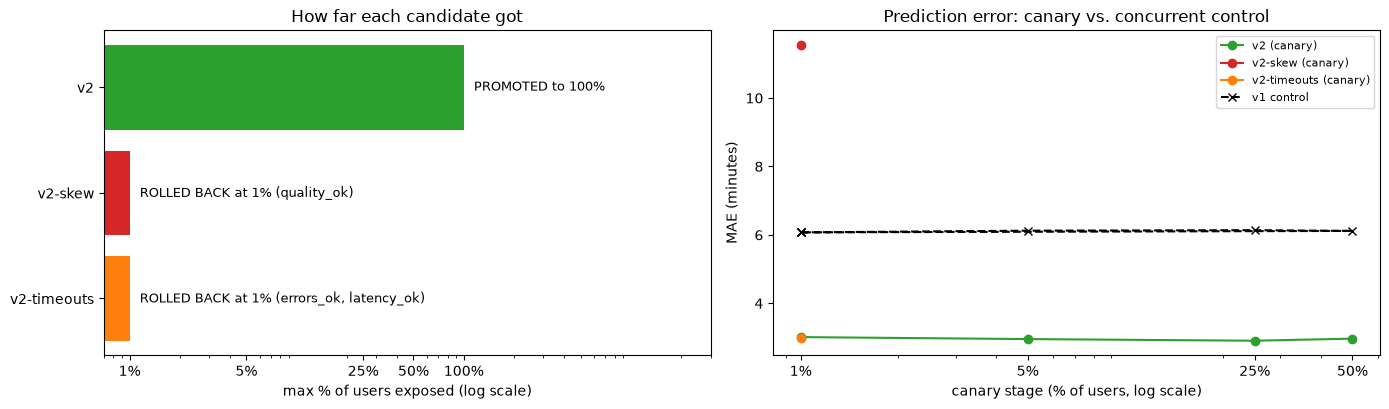

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
colors = {"v2": "tab:green", "v2-skew": "tab:red", "v2-timeouts": "tab:orange"}
for i, (name, hist) in enumerate(canary_history.groupby("candidate", sort=False)):
    reached = 100 if canary_outcomes[name].startswith("PROMOTED") else hist["stage_pct"].iloc[-1]
    reason = "" if reached == 100 else f" ({', '.join(hist['failed_checks'].iloc[-1])})"
    axes[0].barh(i, reached, color=colors[name])
    axes[0].text(reached * 1.15, i, canary_outcomes[name] + reason, va="center", fontsize=9)
    axes[1].plot(hist["stage_pct"], hist["canary_mae"], marker="o", color=colors[name], label=f"{name} (canary)")
axes[0].set_yticks(range(len(CANDIDATES)), list(CANDIDATES)); axes[0].invert_yaxis()
STAGE_TICKS = ([1, 5, 25, 50, 100], ["1%", "5%", "25%", "50%", "100%"])
axes[0].set_xscale("log"); axes[0].set_xlim(0.7, 3_000); axes[0].set_xticks(*STAGE_TICKS)
axes[0].set_xlabel("max % of users exposed (log scale)")
axes[0].set_title("How far each candidate got")
axes[1].plot(canary_history["stage_pct"], canary_history["control_mae"], "k--", marker="x", label="v1 control")
axes[1].set_xscale("log"); axes[1].set_xticks(STAGE_TICKS[0][:-1], STAGE_TICKS[1][:-1]); axes[1].set_xlabel("canary stage (% of users, log scale)"); axes[1].set_ylabel("MAE (minutes)")
axes[1].set_title("Prediction error: canary vs. concurrent control"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What happened:**
- **`v2`** passed every stage and was promoted to 100%. Its MAE is below the concurrent v1 control at every stage.
- **`v2-skew`** was rolled back at the **first** stage (1% of users), on the quality check: its MAE (about 11.5 min) was clearly worse than control (about 6.1 min), and the whole confidence interval of the difference is above zero. 1% of a 20,000-request chunk is only about 200 requests, so the stage had to *extend* to three chunks to collect at least 400 canary requests before deciding. Only that 1% of users ever saw the bad ETAs.
- **`v2-timeouts`** was rolled back at the first stage on the **error-rate** check (about 3% vs. 0.1%), and also on latency: the 200 ms timeouts pushed its p95 just past 1.5x the control's p95. Its prediction quality was fine, which shows why quality alone is not enough.

Two design details worth copying:
- Users in the 1% canary are a **subset** of the 5% canary (because `bucket < 1` implies `bucket < 5`), so nobody flips back and forth between versions as the rollout grows.
- **Guardrails can raise false alarms**: with small samples, a healthy canary can randomly show 3 errors in 400 requests. A good canary system tolerates some noise (our +0.5 pp margin, the "extend" rule) and treats a rollback as cheap, because it is.

In Kubernetes, tools like [Argo Rollouts](https://argoproj.github.io/argo-rollouts/) and [Flagger](https://docs.flagger.app/) automate exactly this loop (traffic steps + metric analysis + automatic rollback); managed ML platforms offer the same idea, e.g. [SageMaker deployment guardrails](https://docs.aws.amazon.com/sagemaker/latest/dg/deployment-guardrails.html) (canary / linear traffic shifting with CloudWatch-alarm rollback).

---
## 7. Blue-green deployment with smoke tests

**Blue-green** keeps two complete production environments. **Blue** serves all traffic (v1). The new version is deployed to the idle **green** environment, tested there with **smoke tests**, and then the router switches **all** traffic at once. Rollback = switch back, which takes seconds because blue is still running ([Martin Fowler: BlueGreenDeployment](https://martinfowler.com/bliki/BlueGreenDeployment.html)).

- **Pro**: instant, clean switch and instant rollback; no mixed versions.
- **Con**: double infrastructure during the switch; **all** users are exposed at once, so the smoke tests must be good.

Our smoke test replays a small **golden set** of recent orders with known delivery times through green, and requires an error rate of at most 1%, latency within the SLO, and MAE no worse than v1 on the same set.

In [11]:
class BlueGreenRouter:
    """Two environments; exactly one is live. Switching is a single pointer change."""

    def __init__(self, blue: Endpoint):
        self.envs = {"blue": blue, "green": None}
        self.live = "blue"

    @property
    def idle(self) -> str:
        return "green" if self.live == "blue" else "blue"

    def deploy_to_idle(self, endpoint: Endpoint) -> None:
        self.envs[self.idle] = endpoint
        log.info("deployed %s to %s (idle, no traffic yet)", endpoint.name, self.idle)

    def smoke_test(self, golden_orders: pd.DataFrame, seed: int = 0) -> tuple[bool, dict]:
        rng = np.random.default_rng(seed)
        new = arm_metrics(self.envs[self.idle].serve(golden_orders, rng), golden_orders["actual_min"])
        ref = arm_metrics(self.envs[self.live].serve(golden_orders, rng), golden_orders["actual_min"])
        checks = {"errors_ok": new["error_rate"] <= 0.01, "latency_ok": new["p95_latency_ms"] <= CFG.latency_slo_p95_ms,
                  "mae_not_worse": new["mae_min"] <= ref["mae_min"]}
        checks = {k: bool(v) for k, v in checks.items()}
        return all(checks.values()), {"idle_mae": round(float(new["mae_min"]), 2),
                                      "live_mae": round(float(ref["mae_min"]), 2),
                                      "idle_errors": round(float(new["error_rate"]), 3), **checks}

    def switch(self) -> None:
        self.live = self.idle
        log.info("SWITCHED: all traffic now on %s (%s)", self.live, self.envs[self.live].name)

    def rollback(self) -> None:
        self.switch()                                       # rolling back is just switching again


smoke_set = make_orders(300, seed=2024)                     # small golden set, replayed before every switch
for name in CANDIDATES:
    router = BlueGreenRouter(V1)
    router.deploy_to_idle(CANDIDATES[name])
    passed, report = router.smoke_test(smoke_set)
    if passed:
        router.switch()
    print(f"{name:12s} smoke test {'PASSED' if passed else 'FAILED'} -> live = {router.envs[router.live].name:12s} {report}")

2026-10-21 17:46:38,169 | INFO | deployed v2 to green (idle, no traffic yet)


2026-10-21 17:46:38,195 | INFO | SWITCHED: all traffic now on green (v2)


2026-10-21 17:46:38,196 | INFO | deployed v2-skew to green (idle, no traffic yet)


2026-10-21 17:46:38,212 | INFO | deployed v2-timeouts to green (idle, no traffic yet)


v2           smoke test PASSED -> live = v2           {'idle_mae': 2.88, 'live_mae': 5.79, 'idle_errors': 0.0, 'errors_ok': True, 'latency_ok': True, 'mae_not_worse': True}
v2-skew      smoke test FAILED -> live = v1           {'idle_mae': 11.77, 'live_mae': 5.79, 'idle_errors': 0.0, 'errors_ok': True, 'latency_ok': True, 'mae_not_worse': False}
v2-timeouts  smoke test FAILED -> live = v1           {'idle_mae': 2.9, 'live_mae': 5.79, 'idle_errors': 0.027, 'errors_ok': False, 'latency_ok': True, 'mae_not_worse': True}


In [12]:
# Rollback drill: after a switch, an alert fires (e.g. complaints spike). One call puts v1 back.
router = BlueGreenRouter(V1)
router.deploy_to_idle(CANDIDATES["v2"])
router.switch()
router.rollback()
print("live after rollback:", router.envs[router.live].name, "| idle (kept warm for a retry):", router.envs[router.idle].name)

2026-10-21 17:46:38,252 | INFO | deployed v2 to green (idle, no traffic yet)


2026-10-21 17:46:38,255 | INFO | SWITCHED: all traffic now on green (v2)


2026-10-21 17:46:38,258 | INFO | SWITCHED: all traffic now on blue (v1)


live after rollback: v1 | idle (kept warm for a retry): v2


With 300 golden orders, the smoke test stopped `v2-skew` (MAE worse) and `v2-timeouts` (error rate above 1%), and let `v2` switch. Note the weakness: a smoke test is **small**. A bug that only appears for 0.1% of requests or only at peak load would pass it. That's why many companies **combine** strategies: shadow first, then a canary, and blue-green-style infrastructure underneath for a fast rollback.

---
## 8. A/B test by user hash

A canary asks *"is the new version safe?"*. An **A/B test** asks *"does it improve the business metric?"*, with a fixed 50/50 split for a planned duration and a proper statistical test at the end (see `../03_Machine_Learning/11_ab_testing/` for the statistics in depth).

Why split by **user hash** and not by flipping a coin per request?
- **Consistency**: a customer who refreshes the page must not see "25 min", then "34 min", then "25 min".
- **Valid statistics**: users are the unit that "experiences" the treatment.
- **Stateless**: any server computes the same assignment, no lookup table needed.

**Primary metric:** late rate (share of orders arriving > 10 min after the promised ETA). **Guardrail:** MAE. First, a **sample ratio mismatch (SRM)** check: if a 50/50 split comes out as 52/48 with lots of data, the assignment is broken (a bug, a bot, a crash in one arm) and the results can't be trusted.

In [13]:
ab_orders = make_orders(60_000, seed=303)                          # one simulated day of traffic
ab_rng = np.random.default_rng(SEED)
in_b = np.array([bucket(u, "eta-ab-2026-10") < 50 for u in ab_orders["user_id"]])   # 50/50 by user
served_a, served_b = V1.serve(ab_orders[~in_b], ab_rng), CANDIDATES["v2"].serve(ab_orders[in_b], ab_rng)

# 1) Sample ratio mismatch check on USERS (the randomisation unit)
users_a, users_b = ab_orders.loc[~in_b, "user_id"].nunique(), ab_orders.loc[in_b, "user_id"].nunique()
srm_p = stats.chisquare([users_a, users_b]).pvalue
print(f"users A={users_a:,} B={users_b:,} | SRM p-value = {srm_p:.3f} -> {'OK' if srm_p > 0.001 else 'SRM! stop and debug'}")

# 2) Primary metric: late rate, with a two-proportion z-test
m_a, m_b = arm_metrics(served_a, ab_orders["actual_min"]), arm_metrics(served_b, ab_orders["actual_min"])
n_a, n_b = (~served_a["failed"]).sum(), (~served_b["failed"]).sum()
p_pool = (m_a["late_rate"] * n_a + m_b["late_rate"] * n_b) / (n_a + n_b)
z = (m_b["late_rate"] - m_a["late_rate"]) / np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
p_value = 2 * stats.norm.sf(abs(z))
p_text = f"{p_value:.1e}" if p_value > 1e-10 else "< 1e-10"                  # avoid printing a rounded 0
print(f"late rate A={m_a['late_rate']:.2%}  B={m_b['late_rate']:.2%}  z={z:.1f}  p-value {p_text}")
pd.DataFrame({"A: v1": m_a, "B: v2": m_b}).T.round(4)

users A=19,000 B=18,955 | SRM p-value = 0.817 -> OK
late rate A=9.63%  B=2.14%  z=-38.9  p-value < 1e-10


,requests,error_rate,p95_latency_ms,mae_min,late_rate
A: v1,30117.0,0.0011,15.7062,6.1045,0.0963
B: v2,29883.0,0.0008,19.3483,2.9853,0.0214


In [14]:
# Why hashing beats a coin flip per request: how many returning users would see BOTH models?
returning = ab_orders[ab_orders.duplicated("user_id", keep=False)]
coin_flip = np.random.default_rng(1).random(len(returning)) < 0.5               # per-request randomisation
saw_both_coin = pd.Series(coin_flip, index=returning.index).groupby(returning["user_id"]).nunique().gt(1).mean()
saw_both_hash = pd.Series(in_b[ab_orders.index.get_indexer(returning.index)],
                          index=returning.index).groupby(returning["user_id"]).nunique().gt(1).mean()
print(f"{returning['user_id'].nunique():,} returning users")
print(f"  coin flip per request: {saw_both_coin:.0%} of them saw BOTH models (inconsistent ETAs)")
print(f"  hash by user          : {saw_both_hash:.0%}")

15,889 returning users
  coin flip per request: 59% of them saw BOTH models (inconsistent ETAs)
  hash by user          : 0%


- The SRM check passes, so the split can be trusted.
- v2 cuts the **late rate** from about 9.6% to about 2.1% of orders, and the p-value is tiny, so the improvement is very unlikely to be chance. The MAE guardrail also improved. In a real test you would fix the duration in advance (e.g. two full weeks, to include weekends), and not stop the first time the p-value dips below 0.05 ("peeking", see `../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb`).
- *Simplification:* we test at the order level although we randomised by user; when users place many orders, a stricter analysis uses user-level aggregates or cluster-robust standard errors.
- With a coin flip per request, most returning users would have seen both models; with hashing, none did.

---
## 9. Feature flags: decouple deploy from release

A **feature flag** is a switch read at runtime from a config service. The code for v1 *and* v2 is deployed; the flag decides who gets what. This separates **deploy** (code is on the servers) from **release** (users see it), and gives you a **kill switch** that works in seconds without a redeploy ([Martin Fowler / Pete Hodgson: Feature Toggles](https://martinfowler.com/articles/feature-toggles.html)).

Typical rules, evaluated in order: kill switch -> internal allow-list (employees test first) -> blocked regions -> percentage rollout by user hash. Products such as LaunchDarkly, Unleash, Flagsmith or the open standard OpenFeature provide this as a service; the core logic is small.

In [15]:
FLAGS = {   # in production: fetched from a flag service every few seconds and cached in memory
    "eta_model_v2": {"enabled": True, "rollout_pct": 20, "salt": "flag-eta-v2",
                     "allow_users": {"u1", "u2", "u3"},           # employees / QA accounts always get v2
                     "deny_zones": {"north"}},                     # e.g. new courier fleet there: wait
}


def flag_on(flags: dict, name: str, user_id: str, zone: str) -> bool:
    """Evaluate a flag for one request. Unknown or disabled flags are OFF (safe default)."""
    rule = flags.get(name)
    if not rule or not rule["enabled"]:
        return False                                              # kill switch
    if user_id in rule["allow_users"]:
        return True
    if zone in rule["deny_zones"]:
        return False
    return bucket(user_id, rule["salt"]) < rule["rollout_pct"]


def share_on_v2(flags: dict, orders: pd.DataFrame) -> pd.Series:
    on = [flag_on(flags, "eta_model_v2", u, z) for u, z in zip(orders["user_id"], orders["zone"])]
    return pd.Series(on, index=orders.index).groupby(orders["zone"]).mean().round(3)


flag_orders = make_orders(20_000, seed=404)
before = share_on_v2(FLAGS, flag_orders)
FLAGS["eta_model_v2"]["enabled"] = False                          # incident! flip the kill switch
after = share_on_v2(FLAGS, flag_orders)
FLAGS["eta_model_v2"]["enabled"] = True                           # restore for later cells
pd.DataFrame({"share on v2 (flag on, 20%)": before, "after kill switch": after})

,"share on v2 (flag on, 20%)",after kill switch
zone,,
center,0.196,0.0
east,0.205,0.0
north,0.000,0.0
south,0.195,0.0
west,0.211,0.0


About 20% of users in every zone get v2, except `north` (denied: 0%). One config change (the kill switch) moves everyone back to v1, with no build, no deploy, no restart.

> **Flag debt:** every flag is an `if` in your code. Once v2 is at 100% and stable, **delete the flag and the v1 code path**. Teams that forget end up with hundreds of stale flags nobody dares to touch.

---
## 10. Which strategy when?

| Strategy | Users at risk | Needs labels? | Extra infra cost | Answers | Typical use |
|---|---|---|---|---|---|
| Batch release gate | none | yes (golden set) | small | "are the new outputs sane?" | nightly / weekly scoring jobs |
| Shadow | **none** | for quality: yes, later | 2x inference during shadow | "does it work on real traffic?" | risky changes, new features / dependencies |
| Canary | small, growing slice | helps (fast labels) | small | "is it safe?" | every routine release |
| Blue-green | all, but instant rollback | no (smoke tests) | 2x environment during switch | "can we switch and switch back fast?" | infra changes, big-bang upgrades |
| A/B test | 50% for weeks | yes | small | "is it **better for the business**?" | model changes meant to move a KPI |
| Feature flag | whoever you choose | no | flag service | "who gets it, and can I turn it off now?" | everything; the switch underneath the others |

A common, mature pipeline: **offline eval -> shadow (days) -> canary (hours) -> A/B test (weeks) -> 100%**, with flags as the kill switch throughout.

---
## 11. The deployment runbook

A **runbook** is the written plan for the release: who, what, when, which checks, and **exactly how to roll back**. It is written *before* the release, so nobody has to think clearly at 3 a.m. during an incident. Generating it from the same config the automation uses keeps the two in sync.

In [16]:
@dataclass
class RolloutPlan:
    model: str = "eta-model"
    from_version: str = "v1"
    to_version: str = "v2"
    owner: str = "ml-platform on-call (#eta-oncall)"
    release_day: str = str(date(2026, 10, 27))
    rollback_command: str = "set flag eta_model_v2.enabled=false  (or: kubectl argo rollouts abort eta-api)"
    cfg: RolloutConfig = field(default_factory=lambda: CFG)


def render_runbook(plan: RolloutPlan, shadow: pd.DataFrame) -> str:
    c = plan.cfg
    sh = shadow.set_index("candidate").loc[plan.to_version]
    stages = " -> ".join(f"{s}%" for s in c.canary_stages_pct) + " -> 100%"
    return f"""### Runbook: {plan.model} {plan.from_version} -> {plan.to_version} ({plan.release_day})
**Owner:** {plan.owner}  |  **Rollback:** `{plan.rollback_command}`

**Before the release**
- [ ] Offline evaluation signed off (MAE, slices by zone and rush hour)
- [ ] Shadow run done: MAE change {sh['mae_change_min']:+.2f} min (CI {sh['ci95']}), mean prediction shift {sh['mean_pred_shift_min']:+.2f} min
- [ ] Dashboards open: error rate, p95 latency, MAE vs. control, late rate, complaints
- [ ] v1 kept deployed and warm for fast rollback; no other release in the same window

**Rollout:** {stages}, at least {c.min_canary_requests} canary requests per stage
- Automatic rollback if: error rate > control + {c.max_error_rate_increase * 100:.1f} percentage points, p95 > {c.latency_slo_p95_ms:.0f} ms or > {c.max_p95_ratio}x control, or MAE CI entirely above control
- If a stage cannot collect enough data after {c.max_chunks_per_stage} chunks: halt and page the owner

**After 100%**
- [ ] Watch for 24 h (includes lunch + dinner peaks), then decommission v1 and delete the flag
- [ ] Post a short release note: what changed, measured impact, any incidents
"""


display(Markdown(render_runbook(RolloutPlan(), shadow_report)))

### Runbook: eta-model v1 -> v2 (2026-10-27)
**Owner:** ml-platform on-call (#eta-oncall)  |  **Rollback:** `set flag eta_model_v2.enabled=false  (or: kubectl argo rollouts abort eta-api)`

**Before the release**
- [ ] Offline evaluation signed off (MAE, slices by zone and rush hour)
- [ ] Shadow run done: MAE change -3.15 min (CI [-3.21, -3.09]), mean prediction shift -0.02 min
- [ ] Dashboards open: error rate, p95 latency, MAE vs. control, late rate, complaints
- [ ] v1 kept deployed and warm for fast rollback; no other release in the same window

**Rollout:** 1% -> 5% -> 25% -> 50% -> 100%, at least 400 canary requests per stage
- Automatic rollback if: error rate > control + 0.5 percentage points, p95 > 50 ms or > 1.5x control, or MAE CI entirely above control
- If a stage cannot collect enough data after 4 chunks: halt and page the owner

**After 100%**
- [ ] Watch for 24 h (includes lunch + dinner peaks), then decommission v1 and delete the flag
- [ ] Post a short release note: what changed, measured impact, any incidents


---
## 12. Automated tests for the rollout machinery

The router and the guardrails are code that decides about production, so they get tests like any other code (run in CI with `pytest`).

In [17]:
def test_bucketing_is_deterministic_and_uniform():
    users = [f"u{i}" for i in range(20_000)]
    first = [bucket(u, "s") for u in users]
    assert first == [bucket(u, "s") for u in users]                           # same answer every time
    counts = np.bincount(first, minlength=100)
    assert stats.chisquare(counts).pvalue > 0.001                             # roughly uniform over 100 buckets


def test_canary_users_stay_in_canary_as_it_grows():
    users = [f"u{i}" for i in range(5_000)]
    at_1 = {u for u in users if bucket(u, "eta-canary") < 1}
    at_5 = {u for u in users if bucket(u, "eta-canary") < 5}
    assert at_1 <= at_5


def test_bad_candidates_are_rolled_back_and_good_one_promoted():
    assert canary_outcomes["v2"].startswith("PROMOTED")
    assert canary_outcomes["v2-skew"].startswith("ROLLED BACK")
    assert canary_outcomes["v2-timeouts"].startswith("ROLLED BACK")


def test_guardrail_extends_when_data_is_too_small():
    tiny = make_orders(100, seed=9)
    rng = np.random.default_rng(0)
    verdict = compare_arms(V1.serve(tiny.iloc[:80], rng), CANDIDATES["v2"].serve(tiny.iloc[80:], rng), tiny["actual_min"])
    assert verdict["decision"] == "extend"


def test_kill_switch_turns_everyone_off():
    flags = {"eta_model_v2": {**FLAGS["eta_model_v2"], "enabled": False}}
    assert not any(flag_on(flags, "eta_model_v2", u, "center") for u in ["u1", "u2", "u99"])


def test_blue_green_rollback_restores_v1():
    r = BlueGreenRouter(V1); r.deploy_to_idle(CANDIDATES["v2"]); r.switch(); r.rollback()
    assert r.envs[r.live].name == "v1"


logging.getLogger("rollout").setLevel(logging.WARNING)       # silence INFO logs from the routers during tests
for test in [test_bucketing_is_deterministic_and_uniform, test_canary_users_stay_in_canary_as_it_grows,
             test_bad_candidates_are_rolled_back_and_good_one_promoted, test_guardrail_extends_when_data_is_too_small,
             test_kill_switch_turns_everyone_off, test_blue_green_rollback_restores_v1]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_bucketing_is_deterministic_and_uniform
PASSED  test_canary_users_stay_in_canary_as_it_grows
PASSED  test_bad_candidates_are_rolled_back_and_good_one_promoted
PASSED  test_guardrail_extends_when_data_is_too_small
PASSED  test_kill_switch_turns_everyone_off
PASSED  test_blue_green_rollback_restores_v1


---
## 13. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Model = model + production behaviour | `Endpoint` with latency, errors, feature bugs | Thinking about serving, not just `.predict()` |
| Batch release gate | Compare outputs + golden set before publishing a table | Nightly/weekly scoring pipelines |
| Shadow deployment | Paired comparison on identical requests, zero user risk | Risky model or feature changes (Uber, Stripe, banks) |
| Canary with guardrails | 1 -> 5 -> 25 -> 50 -> 100% with concurrent control, auto promote / extend / rollback | Argo Rollouts, Flagger, SageMaker guardrails, Google's release tooling |
| Blue-green | Two environments, smoke tests, pointer switch, one-call rollback | Load balancers, Kubernetes services, SageMaker blue/green |
| A/B by user hash | Stable 50/50 split, SRM check, z-test on the business metric | Experimentation platforms (Optimizely, Statsig, in-house) |
| Feature flags | Kill switch, allow-list, region deny, % rollout | LaunchDarkly, Unleash, OpenFeature |
| Runbook as code | Generated from the same config as the automation | Release reviews, on-call handover |
| Tests for the release machinery | Determinism, monotone canary, guardrail behaviour | CI for platform code |

### Practice exercises
1. Add a fourth candidate `v2-slow` with `latency_median_ms=30` and predict which check stops it, and at which stage. Run it.
2. Change `min_canary_requests` to 50. Re-run the canary for `v2` several times with different seeds. Do you ever get a false rollback? What is the trade-off?
3. In the A/B test, compute the late rate per **zone**. Is v2 better everywhere, or only on average? (Simpson's paradox and fairness questions start here.)
4. Make the canary stop early (*fast rollback*) when the error rate is catastrophic (> 10%) even before `min_canary_requests` is reached.
5. Extend `run_shadow` to report the MAE change separately for rush hour and non-rush hour.

### Resources
- Google SRE Workbook: [Canarying Releases](https://sre.google/workbook/canarying-releases/)
- Martin Fowler: [BlueGreenDeployment](https://martinfowler.com/bliki/BlueGreenDeployment.html), [Feature Toggles (Pete Hodgson)](https://martinfowler.com/articles/feature-toggles.html)
- [Argo Rollouts](https://argoproj.github.io/argo-rollouts/) and [Flagger](https://docs.flagger.app/): progressive delivery on Kubernetes
- AWS: [SageMaker deployment guardrails](https://docs.aws.amazon.com/sagemaker/latest/dg/deployment-guardrails.html) (blue/green, canary and linear traffic shifting with auto-rollback)
- [OpenFeature](https://openfeature.dev/): vendor-neutral feature-flag standard
- Kohavi, Tang, Xu: *Trustworthy Online Controlled Experiments* (the A/B testing reference book, including SRM)

### Related notebooks in this repo
- `01_deployment_concepts.ipynb` (strategy overview), `03_serverless_deployment.ipynb`, `message_queues/01_message_queues.ipynb`
- `../12_FastAPI/04_industry_production_ml_api.ipynb`: the API that a rollout would route between
- `../03_Machine_Learning/11_ab_testing/02_industry_ab_test_analysis_report.ipynb`: deeper A/B analysis
- `../15_MLOps/06_monitoring/01_monitoring.ipynb`, `../15_MLOps/05_model_registry/01_model_registry.ipynb`
- `../17_Docker/03_helm_and_gitops.ipynb`: GitOps, the usual way the rollout config itself is deployed